# InsightFlow AI | Financial Performance Analysis
**End-to-End Financial Analytics Case Study · 2024–2025**

**Tools:** Google BigQuery · SQL · Python · pandas · matplotlib · Power BI · DAX  
**Dataset:** `insightflowraw.insightflow_raw.financial_detail` · 216 rows × 19 source columns

## Project Overview
This project evaluates revenue growth, cost pressures, and profitability across three products (Core, Plus, Premium) and three regions (Central, North, South). Calculations are cross-checked against a BigQuery SQL query and a Power BI dashboard.

### Business Questions
1. How did revenue, COGS, and gross margin change between 2024 and 2025?
2. Which products generate the highest revenue and gross margins?
3. Which regions contribute the most gross profit?
4. Do product-level margin patterns vary by region?
5. Are there unusual month-over-month revenue changes?

### Reproducibility and data access
The first code cell authenticates to Google and queries a **private BigQuery project**; readers need their own authorization and access to the dataset. To reproduce this analysis with a local CSV, replace that cell's BigQuery query with `df = pd.read_csv("financial_detail.csv")`. The original dataset is not embedded in this notebook.

**Method:** Revenue = gross sales − discounts; Gross Profit = Revenue − COGS; Gross Margin = Gross Profit / Revenue. All monetary values are in the dataset's units; do not assume a single reporting currency without checking `currency`.
---
## 1. Data Acquisition
Import libraries, authenticate, and load the raw financial data from BigQuery.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import auth
from google.cloud import bigquery

auth.authenticate_user()

client = bigquery.Client(project="insightflowraw")

query = """
SELECT *
FROM `insightflowraw.insightflow_raw.financial_detail`
"""

df = client.query(query).to_dataframe()

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (216, 19)


,month,product,region,currency,units,unit_price,gross_sales,discounts,revenue,cogs,marketing,payroll,other_opex,depreciation,gross_profit,opex,operating_profit,ebitda,year
0,2024-01-01,Core,South,TRY,99,800.0,79200.0,4074.25,75125.75,37620.00,5547.54,14400.0,3005.03,2400.0,37505.75,25352.57,12153.18,14553.18,2024
1,2024-01-01,Plus,South,TRY,62,1400.0,86800.0,3661.52,83138.48,38440.00,5978.86,14400.0,3325.54,2400.0,44698.48,26104.40,18594.08,20994.08,2024
2,2024-01-01,Premium,South,TRY,33,2400.0,79200.0,2200.62,76999.38,34650.00,6468.07,14400.0,3079.98,2400.0,42349.38,26348.05,16001.33,18401.33,2024
3,2024-02-01,Core,South,TRY,101,802.4,81042.4,3143.01,77899.39,38533.52,5895.75,14457.6,3115.98,2400.0,39365.87,25869.33,13496.54,15896.54,2024
4,2024-02-01,Plus,South,TRY,70,1404.2,98294.0,3194.03,95099.97,43573.60,9031.43,14457.6,3804.00,2400.0,51526.37,29693.03,21833.34,24233.34,2024


## 2. Data Quality Assessment
Check source column types, missing values, duplicate rows and numeric ranges. No missing values or identical duplicate rows were observed in the saved run. Identical transactions would require business-key review before deletion.

In [2]:

# INSIGHTFLOW AI - DATA QUALITY ANALYSIS

# 1. Veri setinin boyutu
print("DATASET INFORMATION")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Sütun isimleri ve veri tipleri
print("\nCOLUMN TYPES")
print(df.dtypes)

# 3. Eksik değer kontrolü
print("\nMISSING VALUES")
print(df.isnull().sum())

# 4. Tekrarlanan kayıt kontrolü
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 5. Sayısal veri özeti
print("\nNUMERICAL SUMMARY")
display(df.describe())


DATASET INFORMATION
Rows: 216
Columns: 19

COLUMN TYPES
month                dbdate
product              object
region               object
currency             object
units                 Int64
unit_price          float64
gross_sales         float64
discounts           float64
revenue             float64
cogs                float64
marketing           float64
payroll             float64
other_opex          float64
depreciation        float64
gross_profit        float64
opex                float64
operating_profit    float64
ebitda              float64
year                  Int64
dtype: object

MISSING VALUES
month               0
product             0
region              0
currency            0
units               0
unit_price          0
gross_sales         0
discounts           0
revenue             0
cogs                0
marketing           0
payroll             0
other_opex          0
depreciation        0
gross_profit        0
opex                0
operating_profit    0
ebitda  

,units,unit_price,gross_sales,discounts,revenue,cogs,marketing,payroll,other_opex,depreciation,gross_profit,opex,operating_profit,ebitda,year
count,216.0,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.0
mean,87.236111,1586.233333,114420.283333,4492.006481,109928.276852,52217.930370,9356.393704,18828.000000,4397.131296,3000.000000,57710.346481,35581.525000,22128.821481,25128.821481,2024.5
std,39.677242,685.202658,22939.954042,1621.228414,22185.934352,10421.775972,2030.754119,3123.033877,887.437602,491.035924,12154.320625,6053.293758,7247.654217,7502.644243,0.501161
min,29.0,800.000000,71479.200000,1759.790000,69719.410000,31546.200000,4924.590000,14400.000000,2788.780000,2400.000000,35105.660000,25031.770000,8192.510000,10592.510000,2024.0
25%,49.0,842.600000,96416.400000,3220.105000,93134.172500,44144.280000,7891.782500,15422.400000,3725.365000,2400.000000,48302.787500,29983.660000,16296.537500,19196.685000,2024.0
50%,87.5,1448.300000,113511.200000,4201.585000,108195.080000,52071.080000,9136.030000,18828.000000,4327.800000,3000.000000,56930.175000,35618.885000,21699.945000,24725.520000,2024.5
75%,114.25,2437.800000,130958.100000,5717.485000,125249.542500,59730.240000,10540.560000,22053.600000,5009.985000,3600.000000,65748.702500,41146.360000,26273.047500,29381.495000,2025.0
max,186.0,2565.600000,181412.000000,8805.390000,176345.490000,81492.800000,17161.790000,23587.200000,7053.820000,3600.000000,94852.690000,50711.610000,44141.080000,47741.080000,2025.0


## 3. Financial KPI Validation
Recalculate revenue and gross profit from their underlying components, then compare them with the source's `revenue` and `gross_profit` fields using a 0.01 tolerance. The saved run produced **0 revenue mismatches** and **0 gross-profit mismatches**.

In [3]:

# INSIGHTFLOW AI - FINANCIAL METRICS VALIDATION

# Satır bazında finansal hesaplamalar
df["calculated_revenue"] = df["gross_sales"] - df["discounts"]
df["calculated_gross_profit"] = df["calculated_revenue"] - df["cogs"]

# Toplam KPI hesaplamaları
total_revenue = df["calculated_revenue"].sum()
total_cogs = df["cogs"].sum()
gross_profit = df["calculated_gross_profit"].sum()

gross_margin = (
    gross_profit / total_revenue * 100
    if total_revenue != 0 else np.nan
)

# Hazır finansal sütunlarla tutarlılık kontrolü
revenue_difference = (
    df["calculated_revenue"] - df["revenue"]
).abs()

profit_difference = (
    df["calculated_gross_profit"] - df["gross_profit"]
).abs()

print("INSIGHTFLOW AI - FINANCIAL VALIDATION")
print("-" * 45)

print(f"Total Revenue : {total_revenue:,.2f}")
print(f"Total COGS    : {total_cogs:,.2f}")
print(f"Gross Profit  : {gross_profit:,.2f}")
print(f"Gross Margin  : {gross_margin:.2f}%")

print("\nDATA CONSISTENCY")
print("Revenue mismatches:",
      (revenue_difference > 0.01).sum())
print("Gross Profit mismatches:",
      (profit_difference > 0.01).sum())


INSIGHTFLOW AI - FINANCIAL VALIDATION
---------------------------------------------
Total Revenue : 23,744,507.80
Total COGS    : 11,279,072.96
Gross Profit  : 12,465,434.84
Gross Margin  : 52.50%

DATA CONSISTENCY
Revenue mismatches: 0
Gross Profit mismatches: 0


### Automated assertion checks
Re-run this cell after KPI calculation. These checks will fail visibly if a fundamental financial reconciliation no longer holds.

In [ ]:
assert len(df) == 216, f"Unexpected row count: {len(df)}"
assert df["calculated_revenue"].notna().all()
assert df["calculated_gross_profit"].notna().all()
assert np.allclose(df["calculated_revenue"], df["revenue"], atol=0.01, rtol=0)
assert np.allclose(df["calculated_gross_profit"], df["gross_profit"], atol=0.01, rtol=0)
assert np.isclose(total_revenue - total_cogs, gross_profit, atol=0.01)
print("PASS: row count and core financial reconciliations")

## 4. Year-over-Year Performance
Aggregate 2024 and 2025 results, then calculate percentage growth and gross-margin changes. Growth rates are calculated relative to the prior year.

In [4]:

# INSIGHTFLOW AI - YEAR OVER YEAR ANALYSIS

# Yıllık finansal performans
yearly = (
    df.groupby("year")
    .agg(
        Revenue=("calculated_revenue", "sum"),
        COGS=("cogs", "sum"),
        Gross_Profit=("calculated_gross_profit", "sum")
    )
    .sort_index()
)

# Brüt kâr marjı
yearly["Gross_Margin_%"] = (
    yearly["Gross_Profit"] / yearly["Revenue"] * 100
)

# Yıllık büyüme oranları
yearly["Revenue_Growth_%"] = (
    yearly["Revenue"].pct_change() * 100
)

yearly["COGS_Growth_%"] = (
    yearly["COGS"].pct_change() * 100
)

yearly["Gross_Profit_Growth_%"] = (
    yearly["Gross_Profit"].pct_change() * 100
)

display(yearly.round(2))


,Revenue,COGS,Gross_Profit,Gross_Margin_%,Revenue_Growth_%,COGS_Growth_%,Gross_Profit_Growth_%
year,,,,,,,
2024,11135597.3,5255300.48,5880296.82,52.81,NaN,NaN,NaN
2025,12608910.5,6023772.48,6585138.02,52.23,13.23,14.62,11.99


Finansal yorumumuz
Önceki hesaplamalarımıza göre şirketin gelirleri artıyor ancak maliyetleri daha hızlı büyüyor. Bu nedenle toplam brüt kâr artmasına rağmen brüt kâr marjı düşüyor.

## 5. Product Profitability
Compare total revenue, gross profit, units and revenue contribution by product. Note that revenue leadership and margin leadership are different questions.

In [5]:

# INSIGHTFLOW AI - PRODUCT PROFITABILITY ANALYSIS

product_analysis = (
    df.groupby("product")
    .agg(
        Revenue=("calculated_revenue", "sum"),
        COGS=("cogs", "sum"),
        Gross_Profit=("calculated_gross_profit", "sum"),
        Units_Sold=("units", "sum")
    )
    .reset_index()
)

# Ürün bazlı kâr marjı
product_analysis["Gross_Margin_%"] = (
    product_analysis["Gross_Profit"]
    / product_analysis["Revenue"] * 100
)

# Toplam gelire katkı oranı
product_analysis["Revenue_Share_%"] = (
    product_analysis["Revenue"]
    / product_analysis["Revenue"].sum() * 100
)

# Gelire göre büyükten küçüğe sırala
product_analysis = product_analysis.sort_values(
    "Revenue", ascending=False
)

display(product_analysis.round(2))


,product,Revenue,COGS,Gross_Profit,Units_Sold,Gross_Margin_%,Revenue_Share_%
1,Plus,8761295.94,4073985.28,4687310.66,6279,53.50,36.90
2,Premium,7514823.75,3460850.40,4053973.35,3150,53.95,31.65
0,Core,7468388.11,3744237.28,3724150.83,9414,49.87,31.45


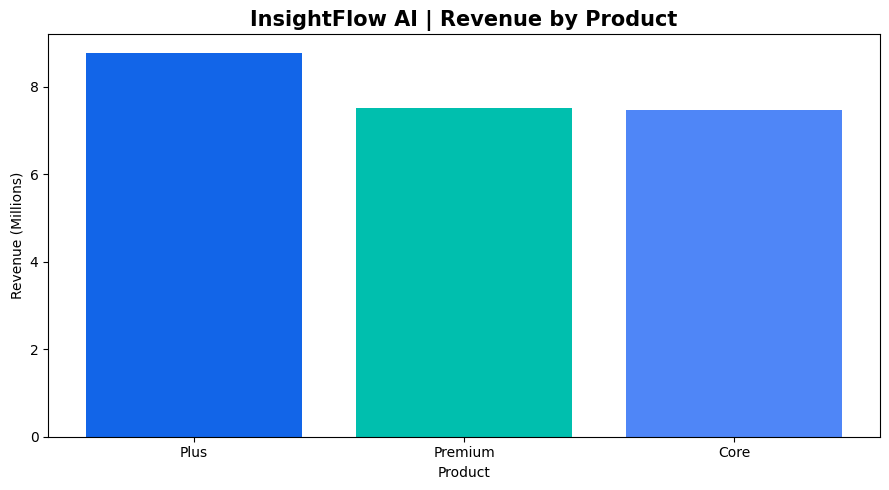

In [6]:

# PRODUCT REVENUE COMPARISON

colors = {
    "Plus": "#1265E8",
    "Premium": "#00BFAE",
    "Core": "#4F86F7"
}

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    product_analysis["product"],
    product_analysis["Revenue"] / 1_000_000,
    color=[
        colors.get(product, "#7AD9F5")
        for product in product_analysis["product"]
    ]
)

ax.set_title(
    "InsightFlow AI | Revenue by Product",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Revenue (Millions)")
ax.set_xlabel("Product")

plt.tight_layout()
plt.show()


## 6. Regional Profitability
Evaluate total gross profit and gross-profit margin by region. Larger regional profit can result from higher revenue volume rather than superior margins.

In [7]:

# INSIGHTFLOW AI - REGIONAL PROFITABILITY ANALYSIS

region_analysis = (
    df.groupby("region")
    .agg(
        Revenue=("calculated_revenue", "sum"),
        COGS=("cogs", "sum"),
        Gross_Profit=("calculated_gross_profit", "sum"),
        Units_Sold=("units", "sum")
    )
    .reset_index()
)

region_analysis["Gross_Margin_%"] = (
    region_analysis["Gross_Profit"]
    / region_analysis["Revenue"] * 100
)

region_analysis["Revenue_Share_%"] = (
    region_analysis["Revenue"]
    / region_analysis["Revenue"].sum() * 100
)

region_analysis = region_analysis.sort_values(
    "Gross_Profit", ascending=False
)

display(region_analysis.round(2))


,region,Revenue,COGS,Gross_Profit,Units_Sold,Gross_Margin_%,Revenue_Share_%
0,Central,9453669.85,4490631.32,4963038.53,7524,52.50,39.81
1,North,7939057.14,3772463.40,4166593.74,6279,52.48,33.44
2,South,6351780.81,3015978.24,3335802.57,5040,52.52,26.75


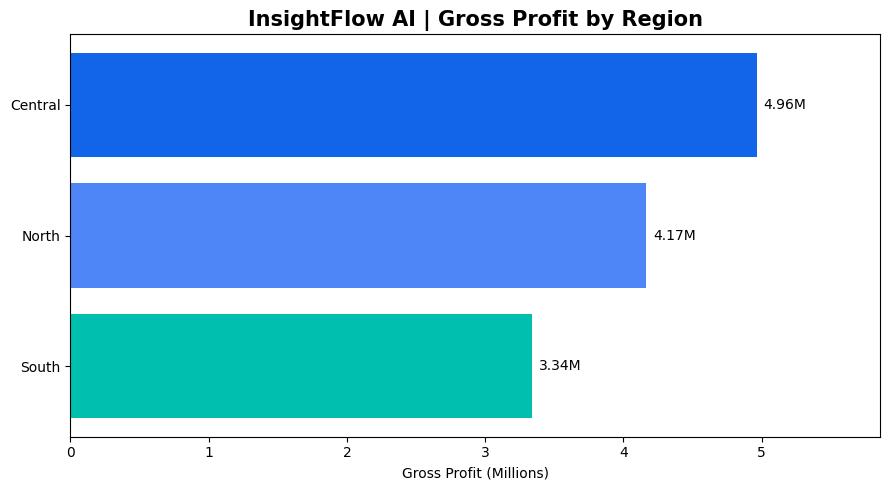

In [8]:

# REGIONAL GROSS PROFIT COMPARISON

region_colors = {
    "Central": "#1265E8",
    "North": "#4F86F7",
    "South": "#00BFAE"
}

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    region_analysis["region"],
    region_analysis["Gross_Profit"] / 1_000_000,
    color=[
        region_colors.get(r, "#7AD9F5")
        for r in region_analysis["region"]
    ]
)

ax.invert_yaxis()
ax.set_title(
    "InsightFlow AI | Gross Profit by Region",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Gross Profit (Millions)")

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}M",
        va="center"
    )

ax.set_xlim(
    0,
    region_analysis["Gross_Profit"].max() / 1_000_000 * 1.18
)

plt.tight_layout()
plt.show()


## 7. Product × Region Margin Analysis
This matrix isolates the profitability variation across the nine product–region combinations. It does not by itself establish whether pricing, discounting or cost structures caused the differences.

In [9]:

# INSIGHTFLOW AI - PRODUCT × REGION ANALYSIS

product_region = (
    df.groupby(["product", "region"])
    .agg(
        Revenue=("calculated_revenue", "sum"),
        COGS=("cogs", "sum"),
        Gross_Profit=("calculated_gross_profit", "sum")
    )
    .reset_index()
)

product_region["Gross_Margin_%"] = np.where(
    product_region["Revenue"] != 0,
    product_region["Gross_Profit"]
    / product_region["Revenue"] * 100,
    np.nan
)

margin_matrix = product_region.pivot(
    index="product",
    columns="region",
    values="Gross_Margin_%"
)

display(margin_matrix.round(2))


region,Central,North,South
product,,,
Core,49.96,49.85,49.74
Plus,53.47,53.50,53.55
Premium,53.94,53.87,54.06


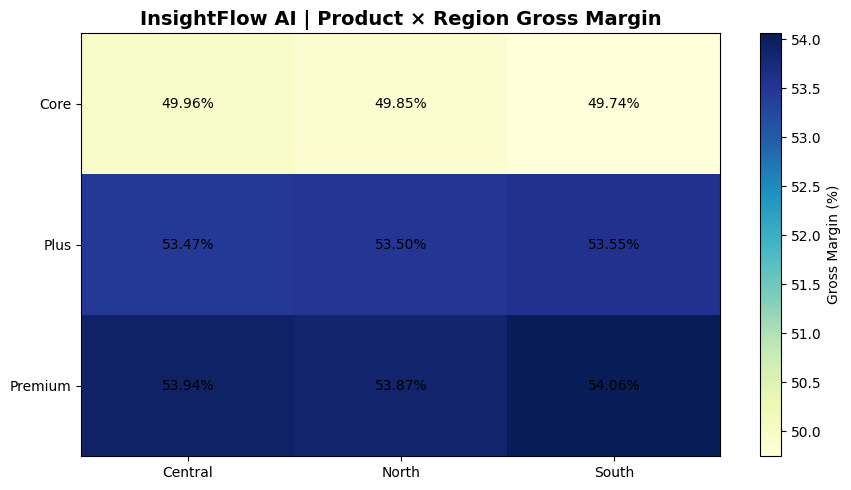

In [10]:

# PRODUCT × REGION PROFITABILITY HEATMAP

fig, ax = plt.subplots(figsize=(9, 5))

values = margin_matrix.to_numpy()

heatmap = ax.imshow(
    values,
    cmap="YlGnBu",
    aspect="auto"
)

ax.set_xticks(range(len(margin_matrix.columns)))
ax.set_xticklabels(margin_matrix.columns)

ax.set_yticks(range(len(margin_matrix.index)))
ax.set_yticklabels(margin_matrix.index)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(
            j, i,
            f"{values[i, j]:.2f}%",
            ha="center",
            va="center",
            color="black"
        )

ax.set_title(
    "InsightFlow AI | Product × Region Gross Margin",
    fontsize=14,
    fontweight="bold"
)

fig.colorbar(heatmap, ax=ax, label="Gross Margin (%)")
plt.tight_layout()
plt.show()


## 8. Monthly Trends and Anomaly Screening
Aggregate monthly results, examine revenue/COGS/profit movements and screen monthly revenue changes with a Z-score threshold of |Z| > 2.

**Limitation:** With only 24 monthly observations, simple Z-scores can miss seasonal patterns or structured changes. An anomaly flag is a screening signal, not proof of an error.

In [11]:

# INSIGHTFLOW AI - MONTHLY FINANCIAL ANALYSIS

df["month"] = pd.to_datetime(df["month"])

monthly_analysis = (
    df.groupby("month")
    .agg(
        Revenue=("calculated_revenue", "sum"),
        COGS=("cogs", "sum"),
        Gross_Profit=("calculated_gross_profit", "sum")
    )
    .sort_index()
)

monthly_analysis["Gross_Margin_%"] = np.where(
    monthly_analysis["Revenue"] != 0,
    monthly_analysis["Gross_Profit"]
    / monthly_analysis["Revenue"] * 100,
    np.nan
)

monthly_analysis["Revenue_MoM_%"] = (
    monthly_analysis["Revenue"].pct_change() * 100
)

display(monthly_analysis.round(2))


,Revenue,COGS,Gross_Profit,Gross_Margin_%,Revenue_MoM_%
month,,,,,
2024-01-01,885983.97,417500.00,468483.97,52.88,NaN
2024-02-01,936643.63,439892.56,496751.07,53.04,5.72
2024-03-01,1001840.66,470302.56,531538.10,53.06,6.96
2024-04-01,1001412.98,472138.48,529274.50,52.85,-0.04
2024-05-01,1003525.00,471738.96,531786.04,52.99,0.21
2024-06-01,981820.80,463324.80,518496.00,52.81,-2.16
2024-07-01,928012.00,439050.24,488961.76,52.69,-5.48
2024-08-01,884438.69,418838.04,465600.65,52.64,-4.70
2024-09-01,870854.86,410581.20,460273.66,52.85,-1.54


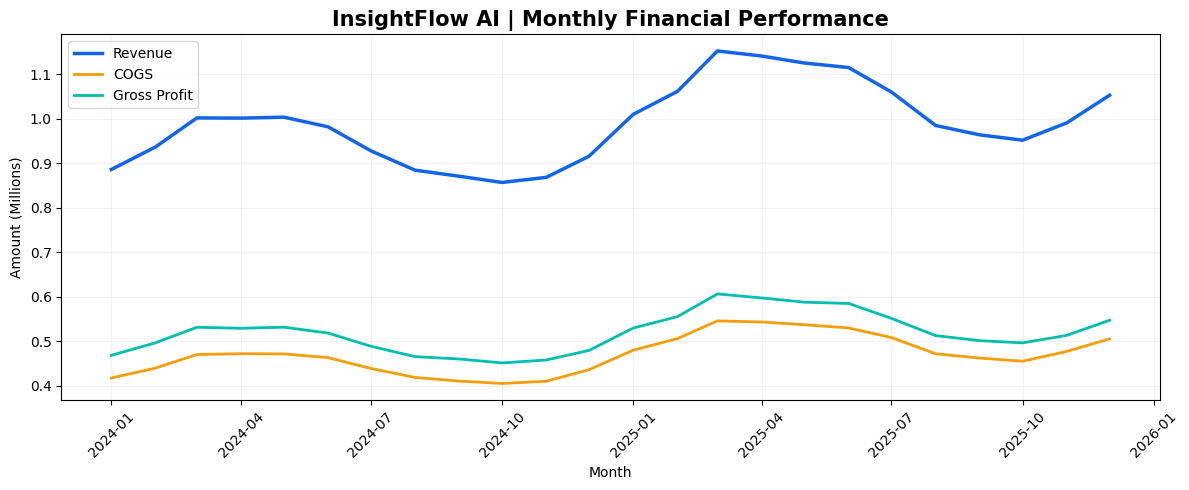

In [12]:

# MONTHLY REVENUE, COGS & GROSS PROFIT TREND

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_analysis.index,
    monthly_analysis["Revenue"] / 1_000_000,
    label="Revenue",
    color="#1265E8",
    linewidth=2.5
)

ax.plot(
    monthly_analysis.index,
    monthly_analysis["COGS"] / 1_000_000,
    label="COGS",
    color="#F59E0B",
    linewidth=2
)

ax.plot(
    monthly_analysis.index,
    monthly_analysis["Gross_Profit"] / 1_000_000,
    label="Gross Profit",
    color="#00BFAE",
    linewidth=2
)

ax.set_title(
    "InsightFlow AI | Monthly Financial Performance",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Amount (Millions)")
ax.set_xlabel("Month")
ax.legend()
ax.grid(alpha=0.15)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# INSIGHTFLOW AI - MONTHLY REVENUE ANOMALY DETECTION

# İlk ay için MoM hesaplanamayacağı için boş değerleri çıkarıyoruz
monthly_changes = monthly_analysis["Revenue_MoM_%"].dropna()

mean_growth = monthly_changes.mean()
std_growth = monthly_changes.std()

if pd.notna(std_growth) and std_growth > 0:
    monthly_analysis["Revenue_MoM_ZScore"] = (
        (monthly_analysis["Revenue_MoM_%"] - mean_growth)
        / std_growth
    )
else:
    monthly_analysis["Revenue_MoM_ZScore"] = np.nan

# |Z-score| > 2 olan ayları potansiyel anomali olarak işaretle
monthly_analysis["Potential_Anomaly"] = (
    monthly_analysis["Revenue_MoM_ZScore"].abs() > 2
)

anomalies = monthly_analysis[
    monthly_analysis["Potential_Anomaly"]
]

print("Potential anomaly count:", len(anomalies))

display(
    monthly_analysis[
        ["Revenue", "Revenue_MoM_%", "Revenue_MoM_ZScore",
         "Potential_Anomaly"]
    ].round(2)
)

print("\nPotential anomalies:")
display(anomalies.round(2))


Potential anomaly count: 0


,Revenue,Revenue_MoM_%,Revenue_MoM_ZScore,Potential_Anomaly
month,,,,
2024-01-01,885983.97,NaN,NaN,False
2024-02-01,936643.63,5.72,1.02,False
2024-03-01,1001840.66,6.96,1.28,False
2024-04-01,1001412.98,-0.04,-0.19,False
2024-05-01,1003525.00,0.21,-0.14,False
2024-06-01,981820.80,-2.16,-0.63,False
2024-07-01,928012.00,-5.48,-1.33,False
2024-08-01,884438.69,-4.70,-1.16,False
2024-09-01,870854.86,-1.54,-0.50,False



Potential anomalies:


,Revenue,COGS,Gross_Profit,Gross_Margin_%,Revenue_MoM_%,Revenue_MoM_ZScore,Potential_Anomaly
month,,,,,,,


Hangi aylarda gelir normal aylık değişimlerden belirgin şekilde sapmış?



Beklenmedik bir düşüş veya yükseliş var mı?



Bu değişimler maliyet ve brüt kâr hareketleriyle birlikte mi gerçekleşmiş?

## 9. Final KPI Summary
Consolidate validated KPIs and the number of flagged months. In the saved run, **no month exceeded the selected Z-score threshold**; this does not establish an absence of all anomalies.

In [14]:

# INSIGHTFLOW AI - FINAL EDA SUMMARY

summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total COGS",
        "Gross Profit",
        "Gross Margin %",
        "Revenue Growth %",
        "COGS Growth %",
        "Products",
        "Regions",
        "Potential Anomalies"
    ],
    "Value": [
        round(total_revenue, 2),
        round(total_cogs, 2),
        round(gross_profit, 2),
        round(gross_margin, 2),
        round(yearly.loc[2025, "Revenue_Growth_%"], 2),
        round(yearly.loc[2025, "COGS_Growth_%"], 2),
        df["product"].nunique(),
        df["region"].nunique(),
        len(anomalies)
    ]
})

display(summary)


,Metric,Value
0,Total Revenue,23744507.80
1,Total COGS,11279072.96
2,Gross Profit,12465434.84
3,Gross Margin %,52.50
4,Revenue Growth %,13.23
5,COGS Growth %,14.62
6,Products,3.00
7,Regions,3.00
8,Potential Anomalies,0.00


## 10. Key Findings and Business Recommendations

| Finding | Verified result | Interpretation |
|---|---|---|
| Revenue growth | +13.23% (2025 vs 2024) | Sales increased |
| COGS growth | +14.62% | Costs increased faster than sales |
| Margin change | 52.81% → 52.23% | Gross margin fell by about 0.58 percentage points |
| Product revenue leader | Plus: 8.76M | Highest aggregate product revenue |
| Product margin leader | Premium: 53.95% | Highest aggregate product gross margin |
| Lowest product margin | Core: 49.87% | Worth investigating pricing and costs |
| Regional gross profit leader | Central: 4.96M | Highest aggregate regional gross profit |
| Z-score screening | 0 months flagged | None exceeded the chosen threshold |

### Recommended next investigations
- Break down COGS and discounts by product and month to investigate margin compression.
- Check Core's unit economics before considering pricing or cost changes.
- Explore whether higher sales volume explains Central's profit leadership.
- Compare seasonal trends across more years before making forecasts.
- Validate source currency conventions before cross-currency aggregation.

### Project limitations
- Source records are aggregated financial observations, not necessarily individual transactions.
- Causal drivers are **hypotheses**, not established facts from this dataset alone.
- dbt models and AI Agent functionality are planned extensions, **not completed components** of this notebook.
- The dataset access requirement makes this notebook not independently executable without an accessible input file or BigQuery permissions.

## Executive Summary

**Project:** InsightFlow AI – Financial Performance Analysis

This project analyzes financial performance across 2024 and 2025 using BigQuery SQL, Python, Power BI, and DAX.

The analysis covers 216 financial records across three product categories and three regions.

### Key Findings

- **Revenue Growth:** Total revenue increased by 13.23% in 2025.
- **Cost Efficiency:** COGS increased by 14.62%, outpacing revenue growth and contributing to a decline in gross profit margin.
- **Product Profitability:** Premium consistently achieved the highest gross profit margins across all three regions, while Core remained below 50%.
- **Regional Performance:** Central generated approximately 39.8% of total gross profit.
- **Financial Trends:** Monthly performance showed a notable revenue peak during spring 2025.

### Business Recommendations

1. Investigate cost growth and its impact on gross profit margins.
2. Review pricing, discounting, and cost structures for the Core product.
3. Evaluate opportunities to improve revenue performance while protecting profitability.
4. Monitor regional and product-level margins to identify emerging risks.

### Conclusion

The analysis demonstrates positive revenue growth alongside increasing cost pressure. Combining SQL validation, Python analysis, and interactive Power BI dashboards provides a structured foundation for financial decision-making.

**Next Development Phase:** AI-powered financial insights and natural-language analytics.
